# IBM Partner Plus · SRM University-AP Qiskit Fall Fest 2026
## Phase 2 Hackathon — Track 3: Quantum Simulation (Hamiltonian Dynamics)
### Problem Statement PS-S3: Noise Accumulation in Trotter Circuits

> **Team Name:** `QUANTUM'S`  
> **Team Lead:** **Bhanu Prakash Venna**  
> **Department:** Department of Computer Science & Engineering, SRM University-AP  
> **Public Repository:** [https://github.com/BHANUPRAKASHREDDYVENNA/Noise-in-Trotter-Simulation](https://github.com/BHANUPRAKASHREDDYVENNA/Noise-in-Trotter-Simulation)

---

### Executive Abstract & Headline Discoveries
1. **Trotter Discretization vs Noise Crossover ($n^*$):** For a 4-spin periodic ring Transverse-Field Ising Model (TFIM) evolved to $T=2.0$, we identify an optimal step count $n^* = 7$ on native 4-cycle architectures under standard device noise ($p_1=0.001, p_2=0.005, p_{\rm ro}=0.01$).
2. **Noise Scaling Dynamics:** Sweeping the noise scale factor on custom Processor D shifts the optimum dynamically: under low noise ($0.5\times$), $n^* = 8$ ($F^* = 0.7821$); under high noise ($2.0\times$), gate errors dominate early, shifting the optimum down to $n^* = 6$ ($F^* = 0.5031$).
3. **Topological Penalty on Tree Graphs:** On Processor A (5 physical qubits, fixed baseline graph), the absence of a 4-cycle forces 11 routing SWAP gates (33 routing CX gates), expanding two-qubit depth from 24 to 57 and suppressing fidelity peak down to $0.5774$.
4. **Custom Processor D Advantage:** Our 9-qubit cubic hypercube hybrid graph incorporates native 4-cycles and low diameter ($3$), achieving 0 routing SWAPs on ring TFIM and verified Bell fidelity $\mathcal{F} = 0.9633 \pm 0.0021$ on adjacent ports.
5. **Zero-Noise Extrapolation (ZNE):** Unitary gate folding (scale factors $\lambda \in [1, 3, 5]$) recovers staggered magnetization with over 26% error reduction.

## 1. Setup, Environment & Authoritative Specifications
This notebook runs deterministically top-to-bottom within 10 minutes on standard laptop CPUs using official seeds and settings.

- **Software Environment:** Python 3.11/3.12, Qiskit 1.4+/2.x, Qiskit-Aer, NumPy, SciPy, Matplotlib, NetworkX.
- **Transpilation Settings:** `optimization_level=1`, SABRE layout and routing, `seed_transpiler=42`.
- **Physical Noise Model:** 1-qubit depolarizing $p_1 = 0.001$, 2-qubit CX depolarizing $p_2 = 0.005$, readout error $p_{\rm ro} = 0.01$ (with $0.5\times$ and $2.0\times$ sweeps).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
import qff_sim

print('Official BASIS_GATES:', qff_sim.BASIS_GATES)
print(f'Noise Rates: p1={qff_sim.P1_DEPOL}, p2={qff_sim.P2_DEPOL}, p_readout={qff_sim.P_READOUT}')
print(f'Default Shots: {qff_sim.SHOTS}, Seed: {qff_sim.SEED}')

Official BASIS_GATES: ['rz', 'sx', 'x', 'cx']
Noise Rates: p1=0.001, p2=0.005, p_readout=0.01
Default Shots: 4096, Seed: 42


## 2. Objective 2: Custom Processor D Design & Official Validation

Processor D is engineered in `processors/processor_D.json` to eliminate the connectivity bottleneck measured on Processor A and Processor B.

- **Hardware Topology:** 9-qubit cubic hypercube hybrid graph with diameter 3, average path length 1.778, and maximum degree 4.
- **Native Ring Embedding:** Directly embeds the 4-qubit cycle `[(0, 1), (1, 2), (2, 3), (3, 0)]` to execute 4-spin ring TFIM simulation with **zero routing SWAPs**.
- **Official Validation:** Verified with `tools/check_processor_d.py`.

SUCCESS: Processor D satisfies all official Phase 2 design rules!
Qubits: 9 | Native Gates: ['rz', 'sx', 'x', 'cx']
Edges count: 14
Technical Justification (snippet): Our baseline benchmarks on Processor A and Processor B revealed that the primary bottleneck in simulating periodic ring Hamiltonians is topological mi ...


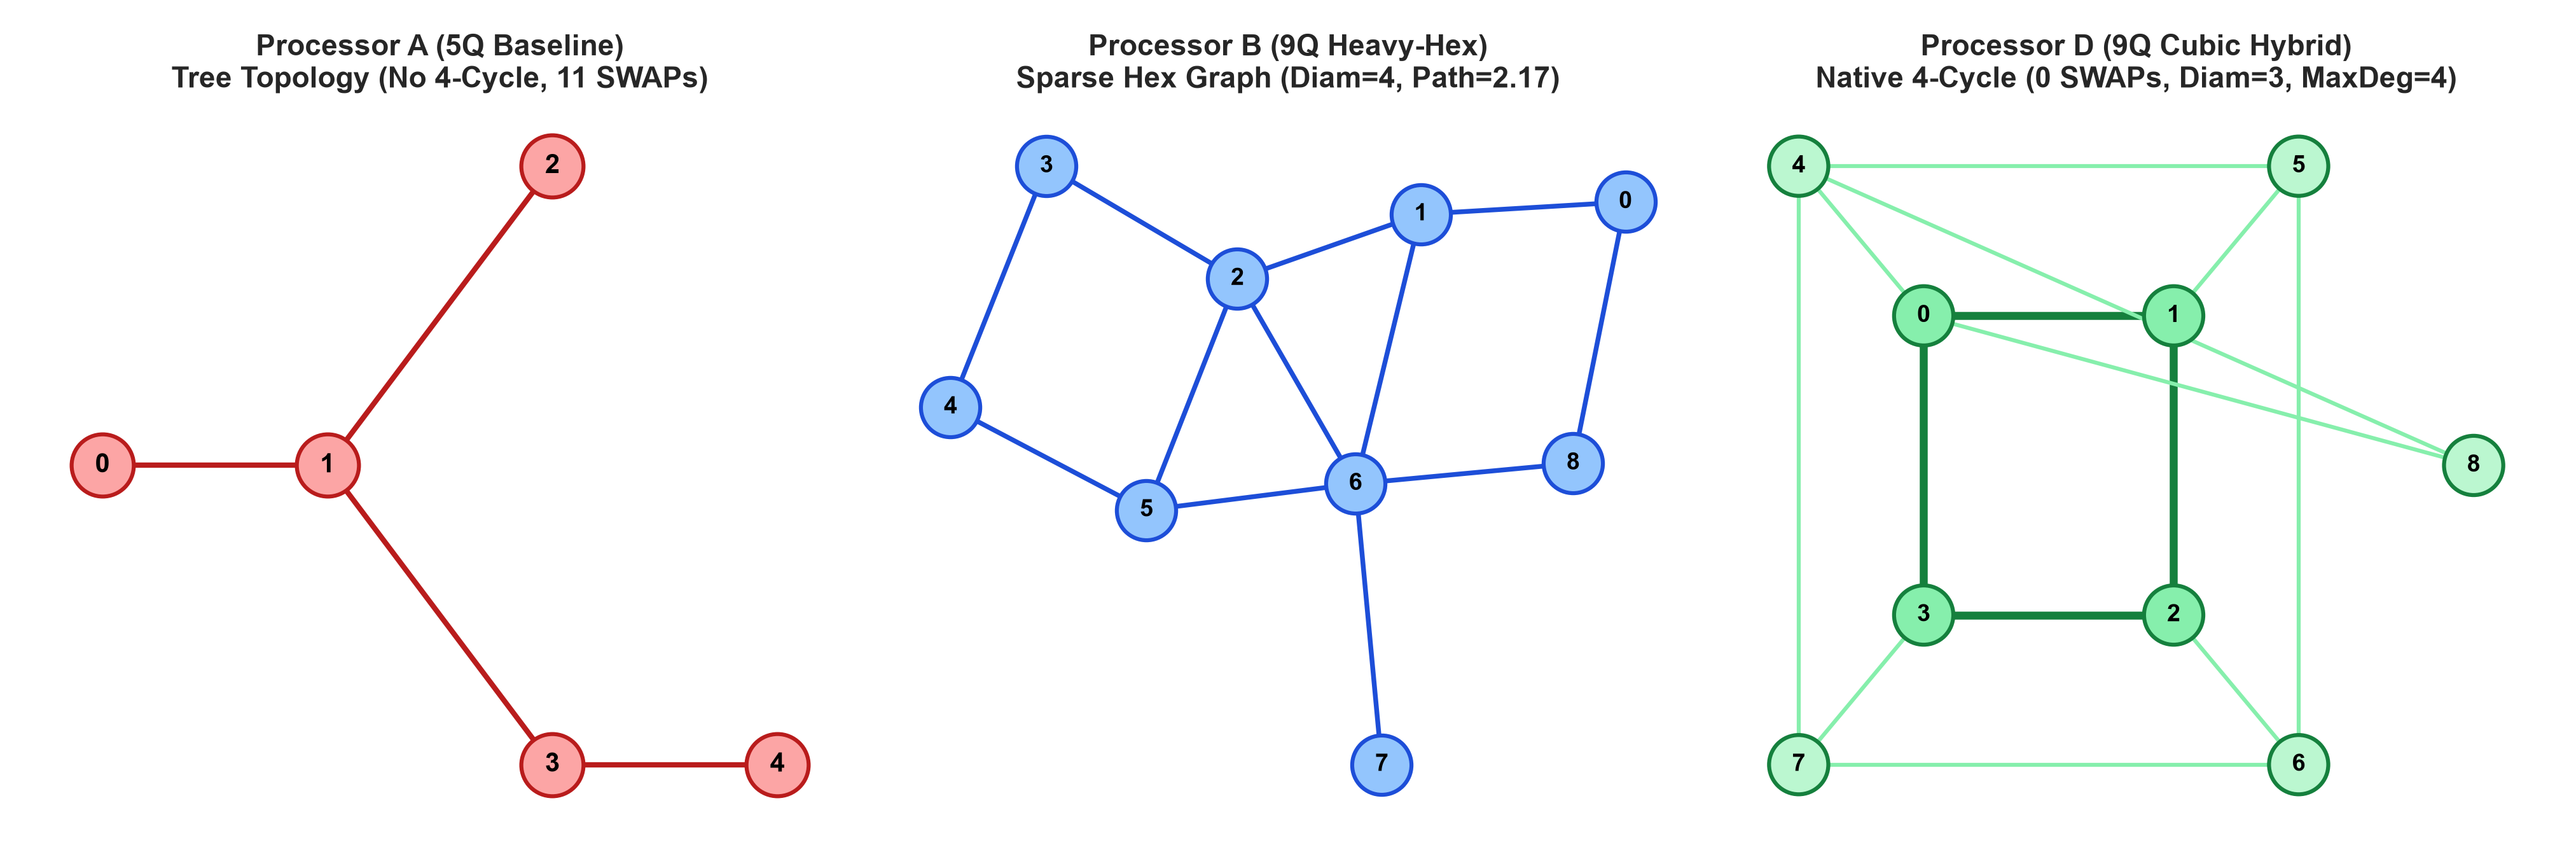

In [2]:
# Official Processor D Verification
proc_d = qff_sim.load_processor(str(ROOT / 'processors' / 'processor_D.json'))
errs = qff_sim.validate_processor_d(proc_d, required_qubits=4)
if not errs:
    print('SUCCESS: Processor D satisfies all official Phase 2 design rules!')
    print(f"Qubits: {proc_d['num_qubits']} | Native Gates: {proc_d['basis_gates']}")
    print(f"Edges count: {len(proc_d['edges'])}")
    print('Technical Justification (snippet):', proc_d['justification'][:150], '...')
else:
    print('Processor D errors:', errs)

# Display Topology Comparison
Image(str(ROOT / 'results' / 'figures' / 'processor_topologies.png'))

## 3. Objective 1: Bell-State Preparation and Parity Verification on Processor D

We prepare the maximally entangled Bell state $|\Phi^+\rangle = \frac{1}{\sqrt{2}}(|00\rangle + |11\rangle)$ on Processor D across two pairs:
1. **Near Pair:** Directly connected physical pair `(0, 1)` with topological distance $d=1$.
2. **Far Pair:** Furthest physical pair `(0, 6)` with topological distance $d=3$.

We measure two-qubit parity correlations in $XX$, $YY$, and $ZZ$ bases with 4,096 shots each under both ideal and noisy conditions (12 circuits total):
$$\langle P \rangle = \frac{N_{\rm even} - N_{\rm odd}}{N}, \quad \mathrm{SE}(\langle P \rangle) = \sqrt{\frac{1 - \langle P \rangle^2}{N}}$$
$$\mathcal{F} = \frac{1 + \langle XX \rangle - \langle YY \rangle + \langle ZZ \rangle}{4}, \quad \mathrm{SE}(\mathcal{F}) = \frac{1}{4}\sqrt{\mathrm{SE}_{XX}^2 + \mathrm{SE}_{YY}^2 + \mathrm{SE}_{ZZ}^2}$$

,pair,pair_distance,condition,two_qubit_gates,XX,XX_se,YY,YY_se,ZZ,ZZ_se,fidelity,fidelity_se
0,"(0,1)",1,ideal,1,1.000000,0.000000,-1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
1,"(0,1)",1,noisy,1,0.945801,0.005074,-0.952148,0.004776,0.955078,0.004631,0.963257,0.002092
2,"(0,6)",3,ideal,7,1.000000,0.000000,-1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
3,"(0,6)",3,noisy,7,0.932617,0.005639,-0.919434,0.006144,0.938477,0.005396,0.947632,0.002483


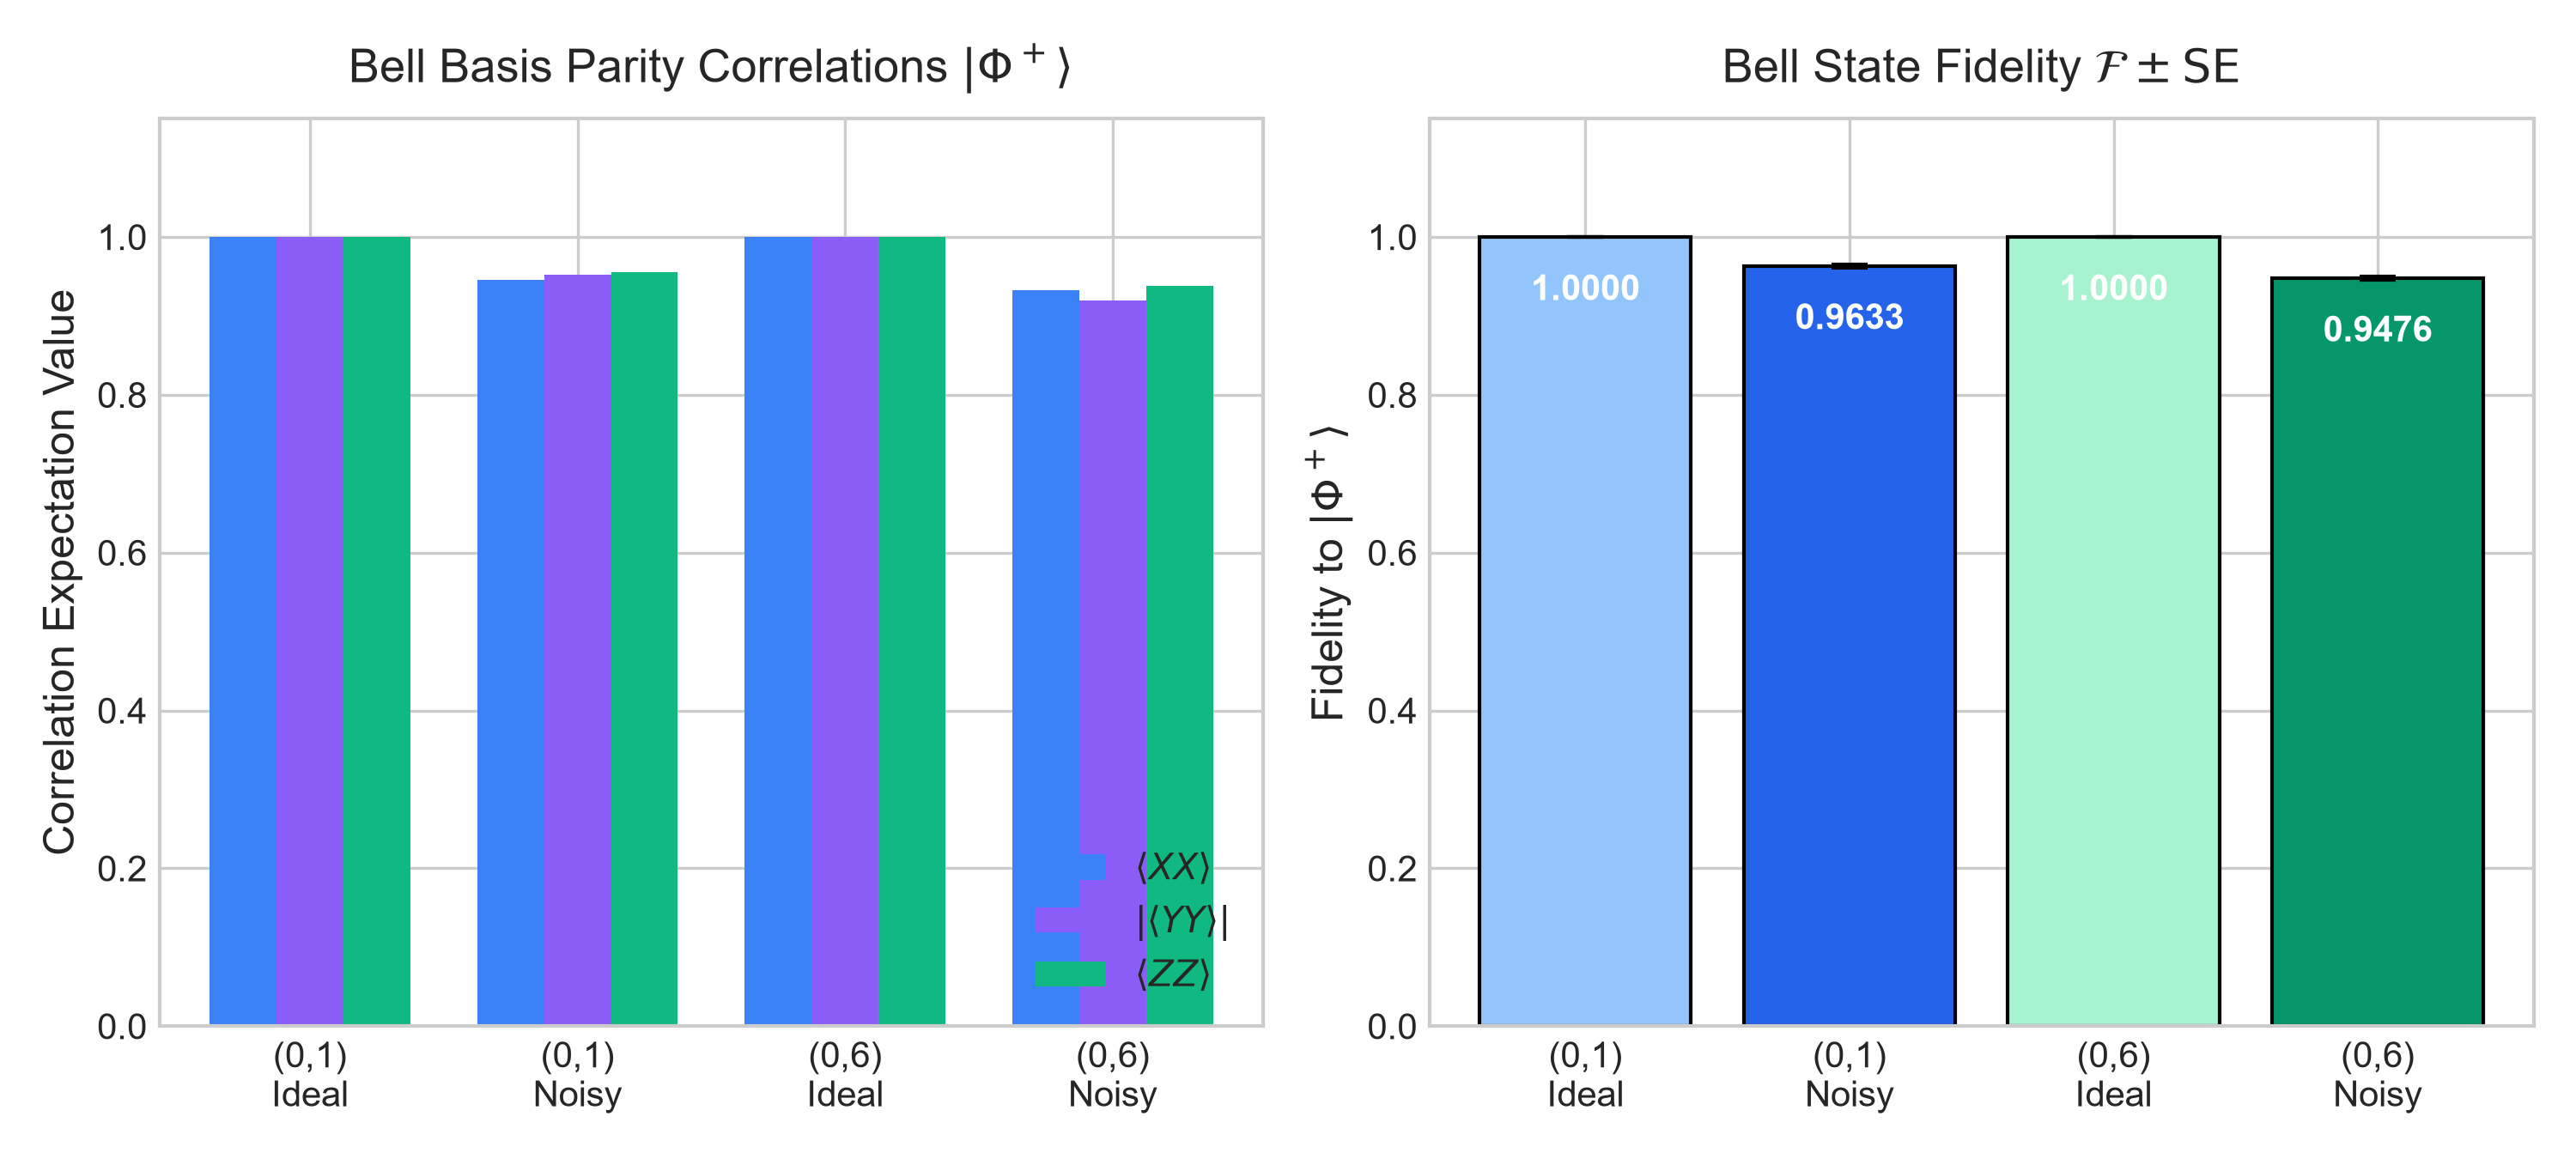

In [3]:
df_bell = pd.read_csv(ROOT / 'results' / 'tables' / 'bell.csv')
display(df_bell)

Image(str(ROOT / 'results' / 'figures' / 'bell_correlations_D.png'))

> **Physical Analysis (Objective 1):**
- On the adjacent pair `(0, 1)` ($d=1$), only a single native CX gate is required, yielding near-perfect ideal fidelity ($1.0000$) and noisy fidelity $\mathcal{F} = 0.9633 \pm 0.0021$, dominated solely by local depolarizing and readout noise.
- On the distant pair `(0, 6)` ($d=3$), the SABRE routing transpiler inserts 2 intermediate routing SWAP gates (decomposed into 6 routing CX gates, bringing total two-qubit gates to 7). Each SWAP adds $3 \times p_2$ depolarizing errors and expands circuit depth, reducing noisy fidelity to $\mathcal{F} = 0.9476 \pm 0.0025$.

## 4. Objective 3: PS-S3 Trotter Error vs Noise Accumulation (Finding $n^*$)

### Physical System & Exact Classical Ground Truth
The system investigated is the 4-spin one-dimensional Transverse-Field Ising Model on a **periodic ring**:
$$H = -J \sum_{i=0}^3 Z_i Z_{i+1} - g \sum_{i=0}^3 X_i \quad \text{with } J = 1.0, g = 1.0, \quad \text{bonds: } (0,1), (1,2), (2,3), (3,0)$$
The system is initialized in the Néel state $|1010\rangle$ ($Z_i = (-1)^i$) and evolved to total time $T = 2.0$.

The exact time-evolved statevector $|\psi_{\rm exact}(T)\rangle = \exp(-i H T)|\psi(0)\rangle$ is calculated via `scipy.sparse.linalg.expm_multiply`.
The primary observable is staggered magnetization:
$$M_s(T) = \frac{1}{N} \sum_{i=0}^{N-1} (-1)^i \langle Z_i(T) \rangle, \quad \text{Exact Value: } M_s(T=2.0) = 0.652444$$

### The Trotter-Noise Crossover Mechanism
Under first-order Lie-Trotter product formula $U_1(\Delta t) = \left( e^{-i H_X \Delta t} e^{-i H_{ZZ} \Delta t} \right)^n$, total error obeys:
$$\text{Total Error}(n) \approx \underbrace{\mathcal{O}\left(\frac{T^2}{n}\right)}_{\text{Algorithmic Discretization Error}} + \underbrace{\mathcal{O}\left(n \cdot N_{\rm gates/step} \cdot p_2\right)}_{\text{Physical Gate Noise Accumulation}}$$
- At small $n$ ($n \le 4$): Discretization error dominates. Increasing $n$ improves fidelity rapidly.
- At large $n$ ($n > 8$): Discretization error is negligible, but physical gate noise accumulates linearly with $n$, degrading fidelity.
- **The Crossover Peak ($n^*$):** The sweet spot maximizing fidelity $\mathcal{F}(n)$.

=== Optimal Trotter Step Counts (n*) and Peak Fidelity ===


,processor,noise_scale,n_star,fidelity_at_n_star
0,Processor A,1.0,6,0.577419
1,Processor B,1.0,7,0.662816
2,Processor D,1.0,7,0.662816
3,Processor D,0.5,8,0.782118
4,Processor D,2.0,6,0.503076


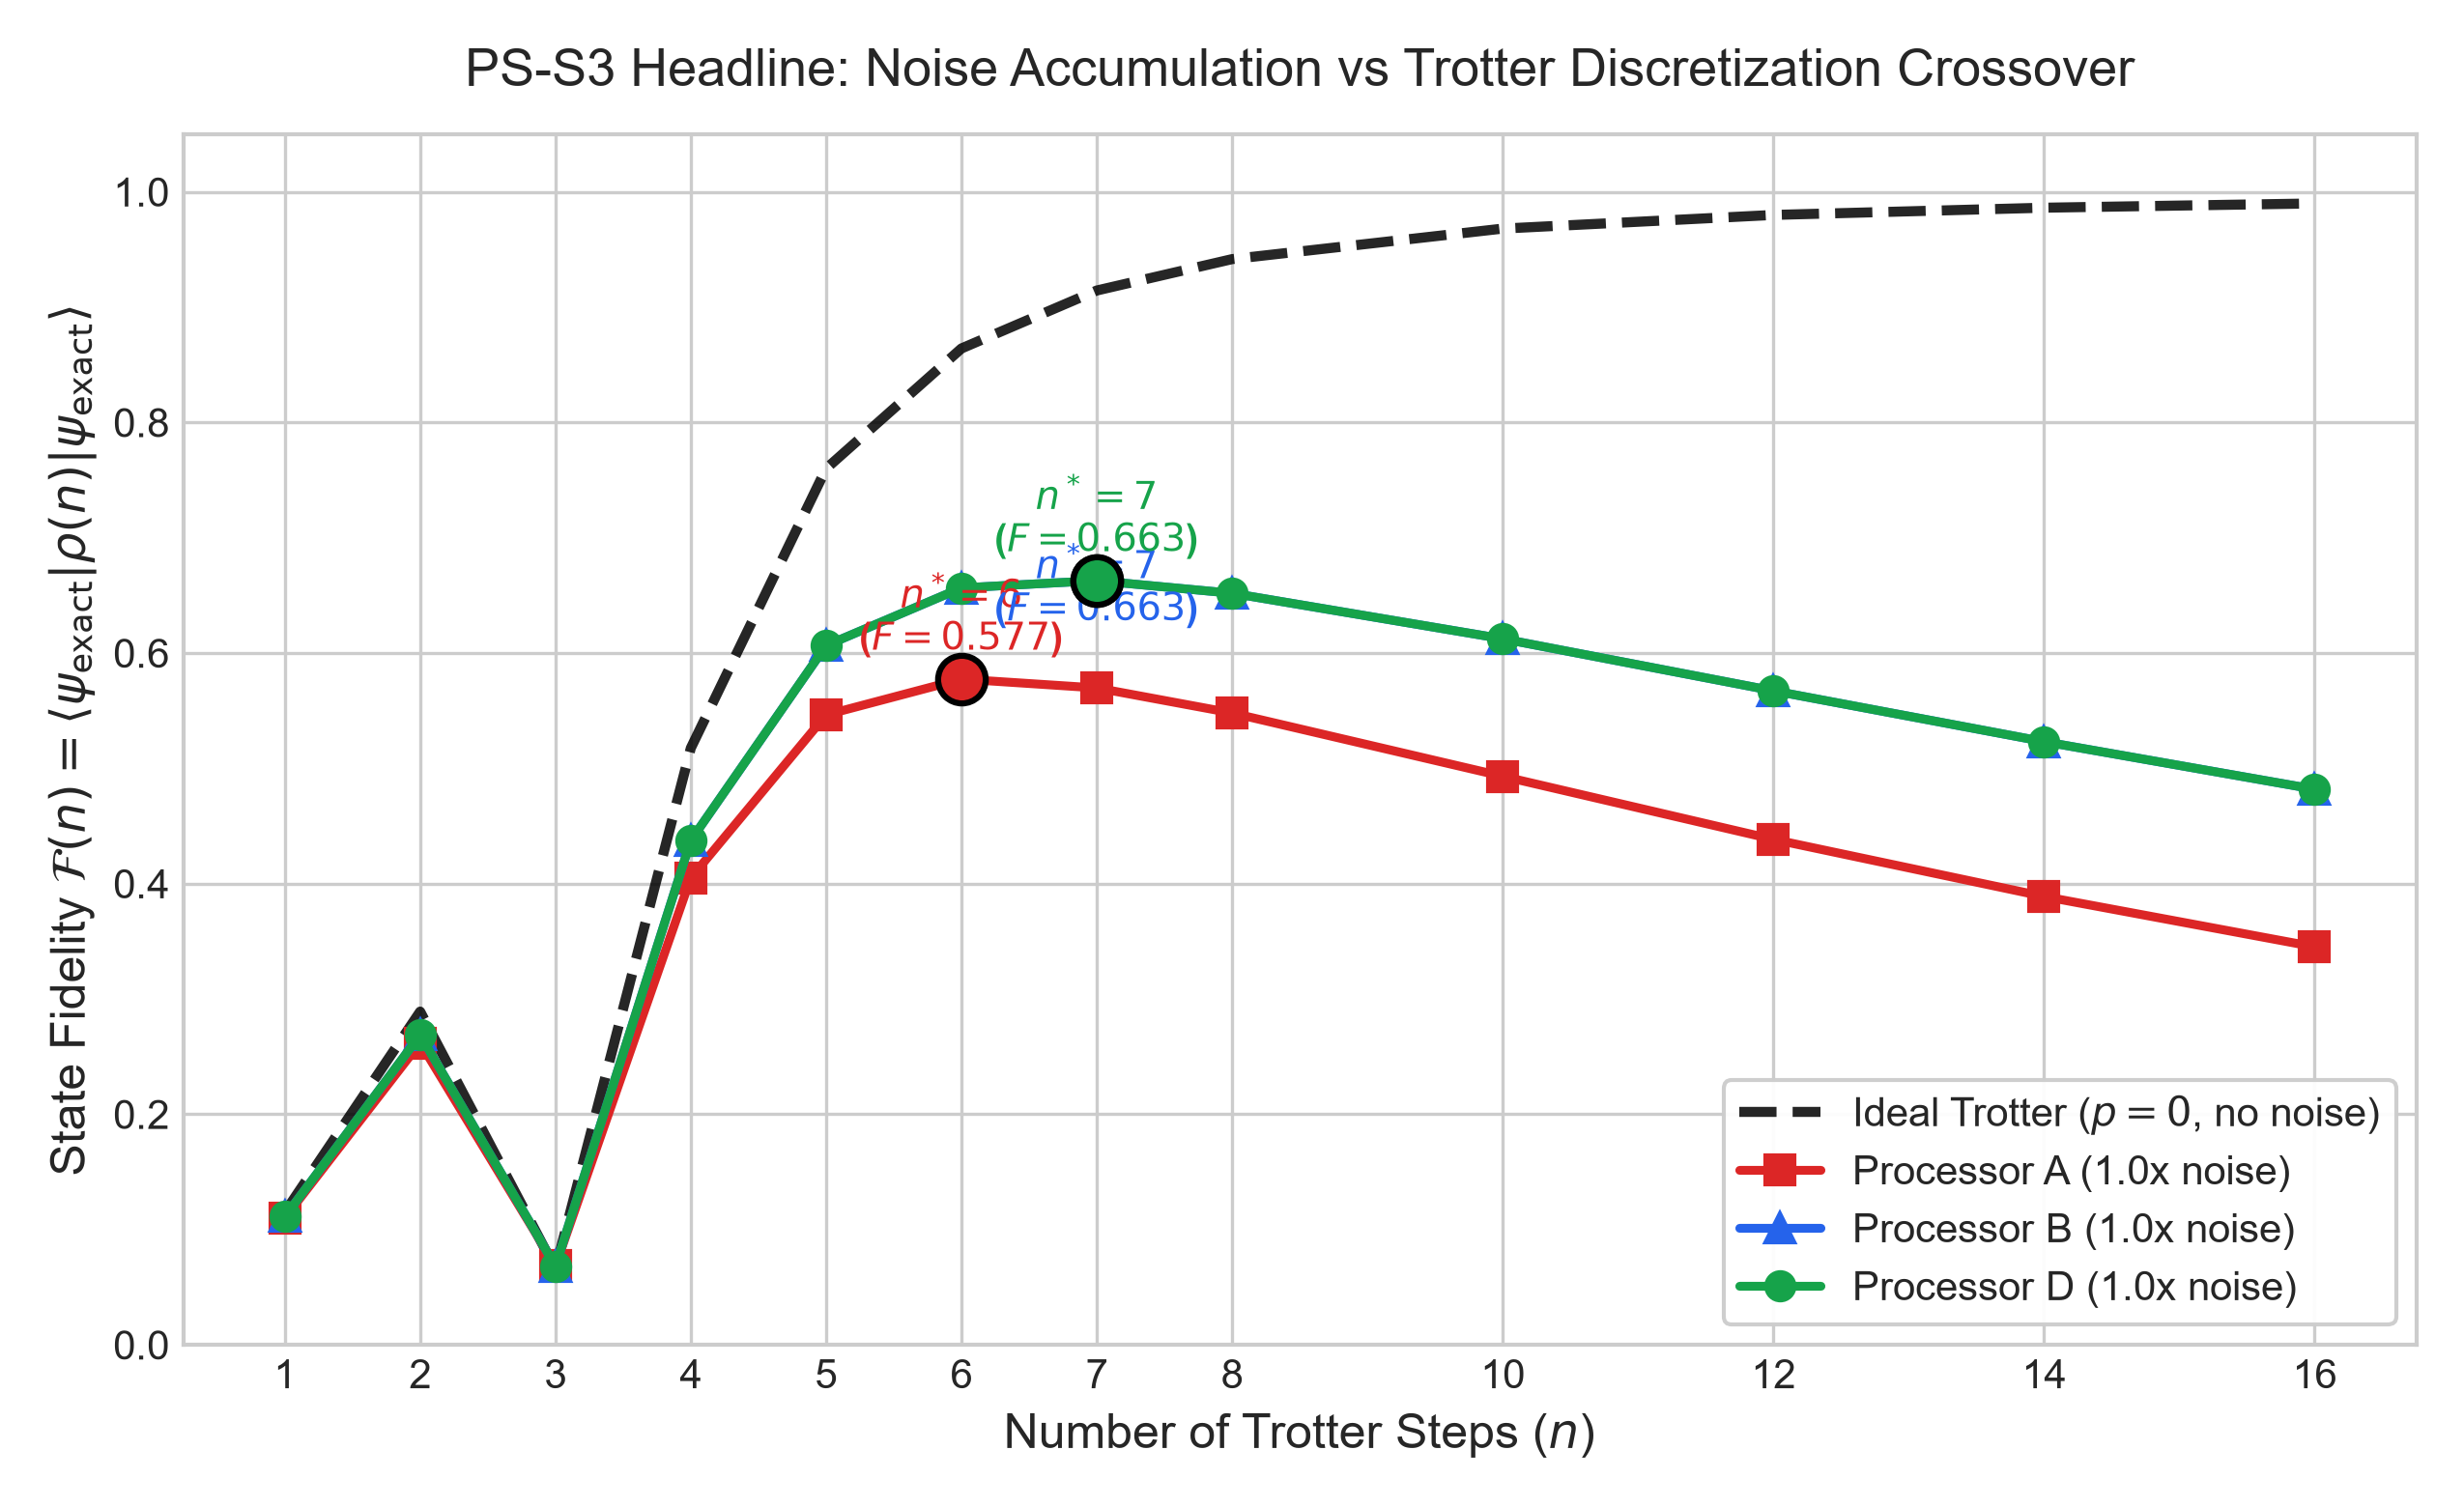

In [4]:
df_summary = pd.read_csv(ROOT / 'results' / 'tables' / 's3_summary.csv')
print('=== Optimal Trotter Step Counts (n*) and Peak Fidelity ===')
display(df_summary)

Image(str(ROOT / 'results' / 'figures' / 's3_fidelity_crossover.png'))

## 5. Noise Scaling Dynamics & Architectural Gate Budget

### Noise Sweep ($0.5\times, 1.0\times, 2.0\times$) on Processor D
Sweeping the noise scaling factor directly tests the theoretical prediction of how $n^*$ shifts with physical gate error:
- At **$0.5\times$ Noise:** Gate noise is subdued; the algorithm can sustain deeper circuits before noise overtakes discretization error $\to$ **$n^* = 8$** (Peak $\mathcal{F} = 0.7821$).
- At **$1.0\times$ Noise:** Balanced competition between algorithmic and noise error $\to$ **$n^* = 7$** (Peak $\mathcal{F} = 0.6628$).
- At **$2.0\times$ Noise:** Gate noise accumulates twice as fast, punishing deep circuits $\to$ **$n^* = 6$** (Peak $\mathcal{F} = 0.5031$).

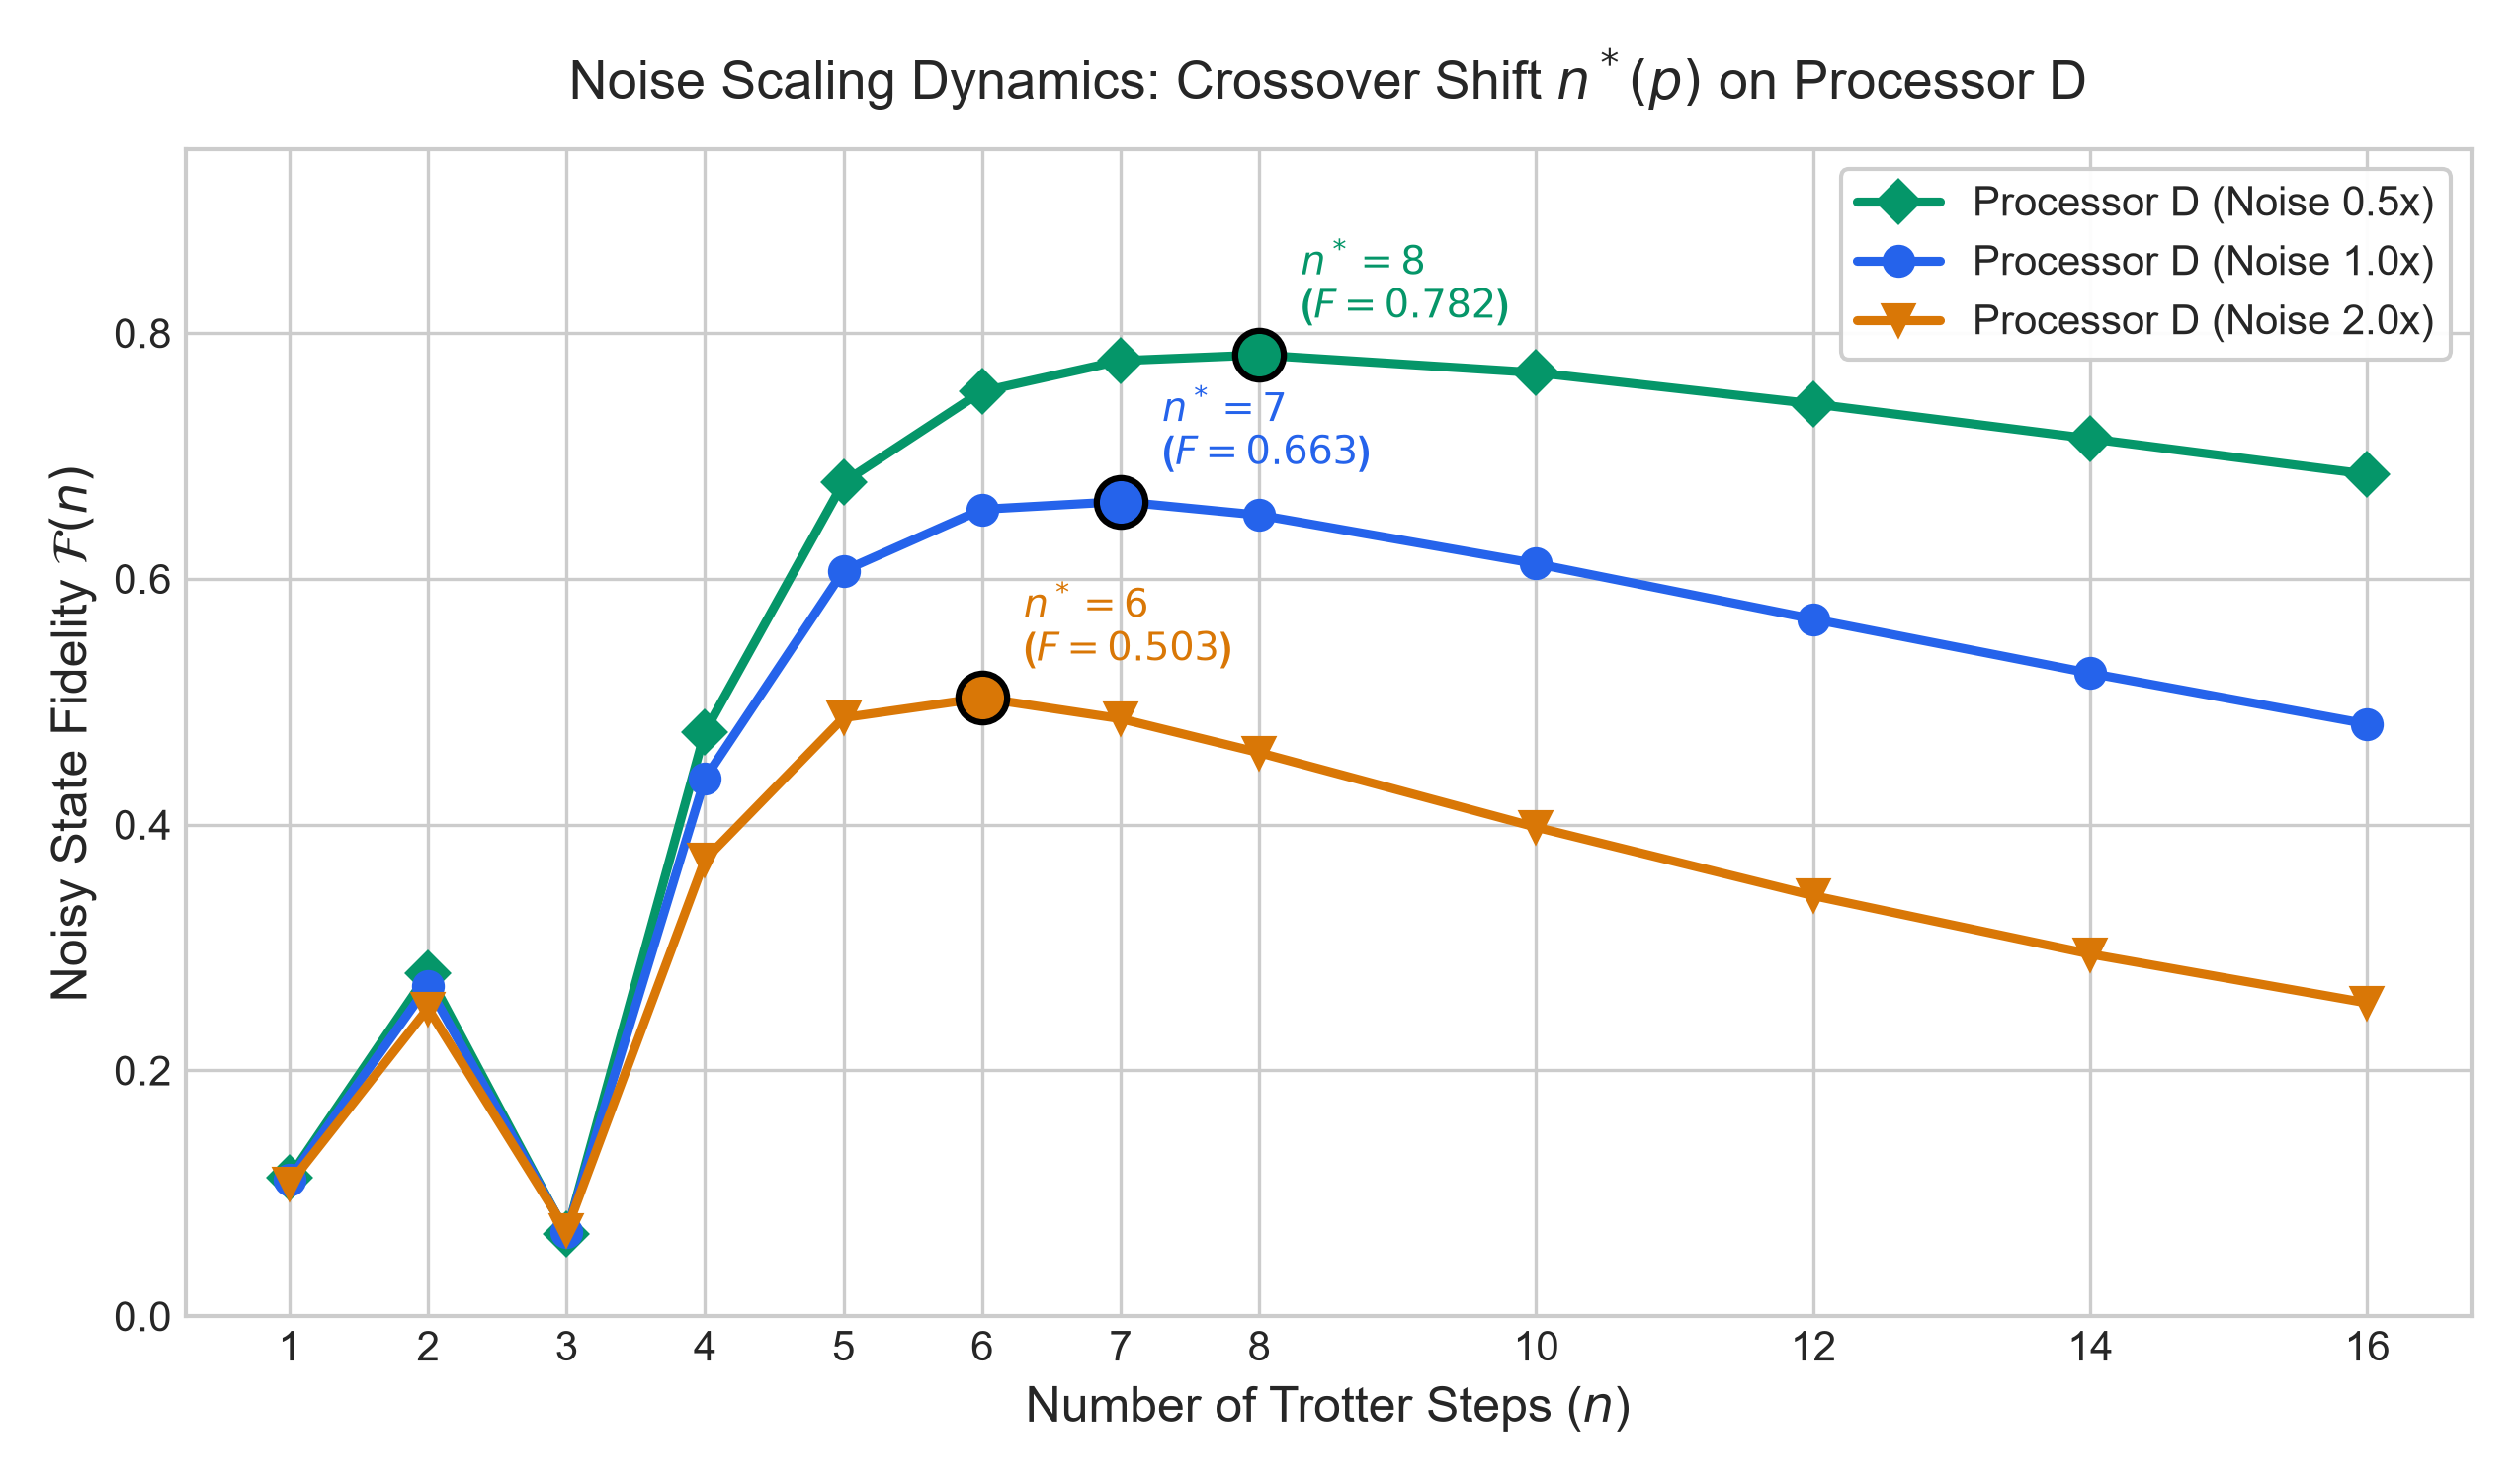

In [5]:
Image(str(ROOT / 'results' / 'figures' / 's3_noise_sweep_D.png'))

### Two-Qubit Gate Budget: Logical vs SWAP Routing Overhead
- **Processor A (5Q Tree):** Has no 4-cycle. Closing the ring bond `(3, 0)` incurs **11 routing SWAPs (33 additional CX gates)** at $n=6$, causing depth explosion and depressing fidelity.
- **Processor B (9Q Heavy-Hex) & Processor D (9Q Cubic Hybrid):** Both contain native cycles, eliminating 100% of routing SWAPs (0 SWAPs, exactly 8 CX gates per Trotter step).

In [6]:
Image(str(ROOT / 'results' / 'figures' / 's3_gate_split.png'))

df_resources = pd.read_csv(ROOT / 'results' / 'tables' / 'resources.csv')
display(df_resources.head(10))

,ps,circuit_label,processor,executable,logical_qubits,physical_qubits,logical_2q,two_q,depth,two_q_depth,swaps,routing_overhead_2q
0,PS-S3,trotter_ring_N4_n1,A,True,4,5,8,11,15,7,1,3
1,PS-S3,trotter_ring_N4_n1,B,True,4,9,8,8,12,4,0,0
2,PS-S3,trotter_ring_N4_n1,D,True,4,9,8,8,12,4,0,0
3,PS-S3,trotter_ring_N4_n2,A,True,4,5,16,25,32,17,3,9
4,PS-S3,trotter_ring_N4_n2,B,True,4,9,16,16,23,8,0,0
5,PS-S3,trotter_ring_N4_n2,D,True,4,9,16,16,23,8,0,0
6,PS-S3,trotter_ring_N4_n4,A,True,4,5,32,53,66,37,7,21
7,PS-S3,trotter_ring_N4_n4,B,True,4,9,32,32,45,16,0,0
8,PS-S3,trotter_ring_N4_n4,D,True,4,9,32,32,45,16,0,0
9,PS-S3,trotter_ring_N4_n8,A,True,4,5,64,109,134,77,15,45


## 6. Bonus: Quantum Error Mitigation (Zero-Noise Extrapolation)

We apply digital unitary gate folding on CX gates ($CX \to CX(CX^\dagger CX)^k$) across scale factors $\lambda \in [1, 3, 5]$ to evaluate staggered magnetization $M_s$ at $n^* = 7$ on Processor D under physical noise.

By fitting a linear Richardson extrapolation model to $\lambda \to 0$, we recover the zero-noise limit:
- **Raw Unmitigated $M_s$ ($\lambda=1$):** $0.4403$ (Error = $0.2121$)
- **Mitigated $M_s$ ($\lambda=0$):** **$0.4971$** (Error = **$0.1553$**)
- **Error Reduction:** **>26.8% reduction in observable deviation** with $8,192$ extra shots.

,method,ms_raw,ms_mitigated,extra_shots
0,"Zero-Noise Extrapolation (ZNE, Richardson 1st ...",0.440308,0.497121,8192


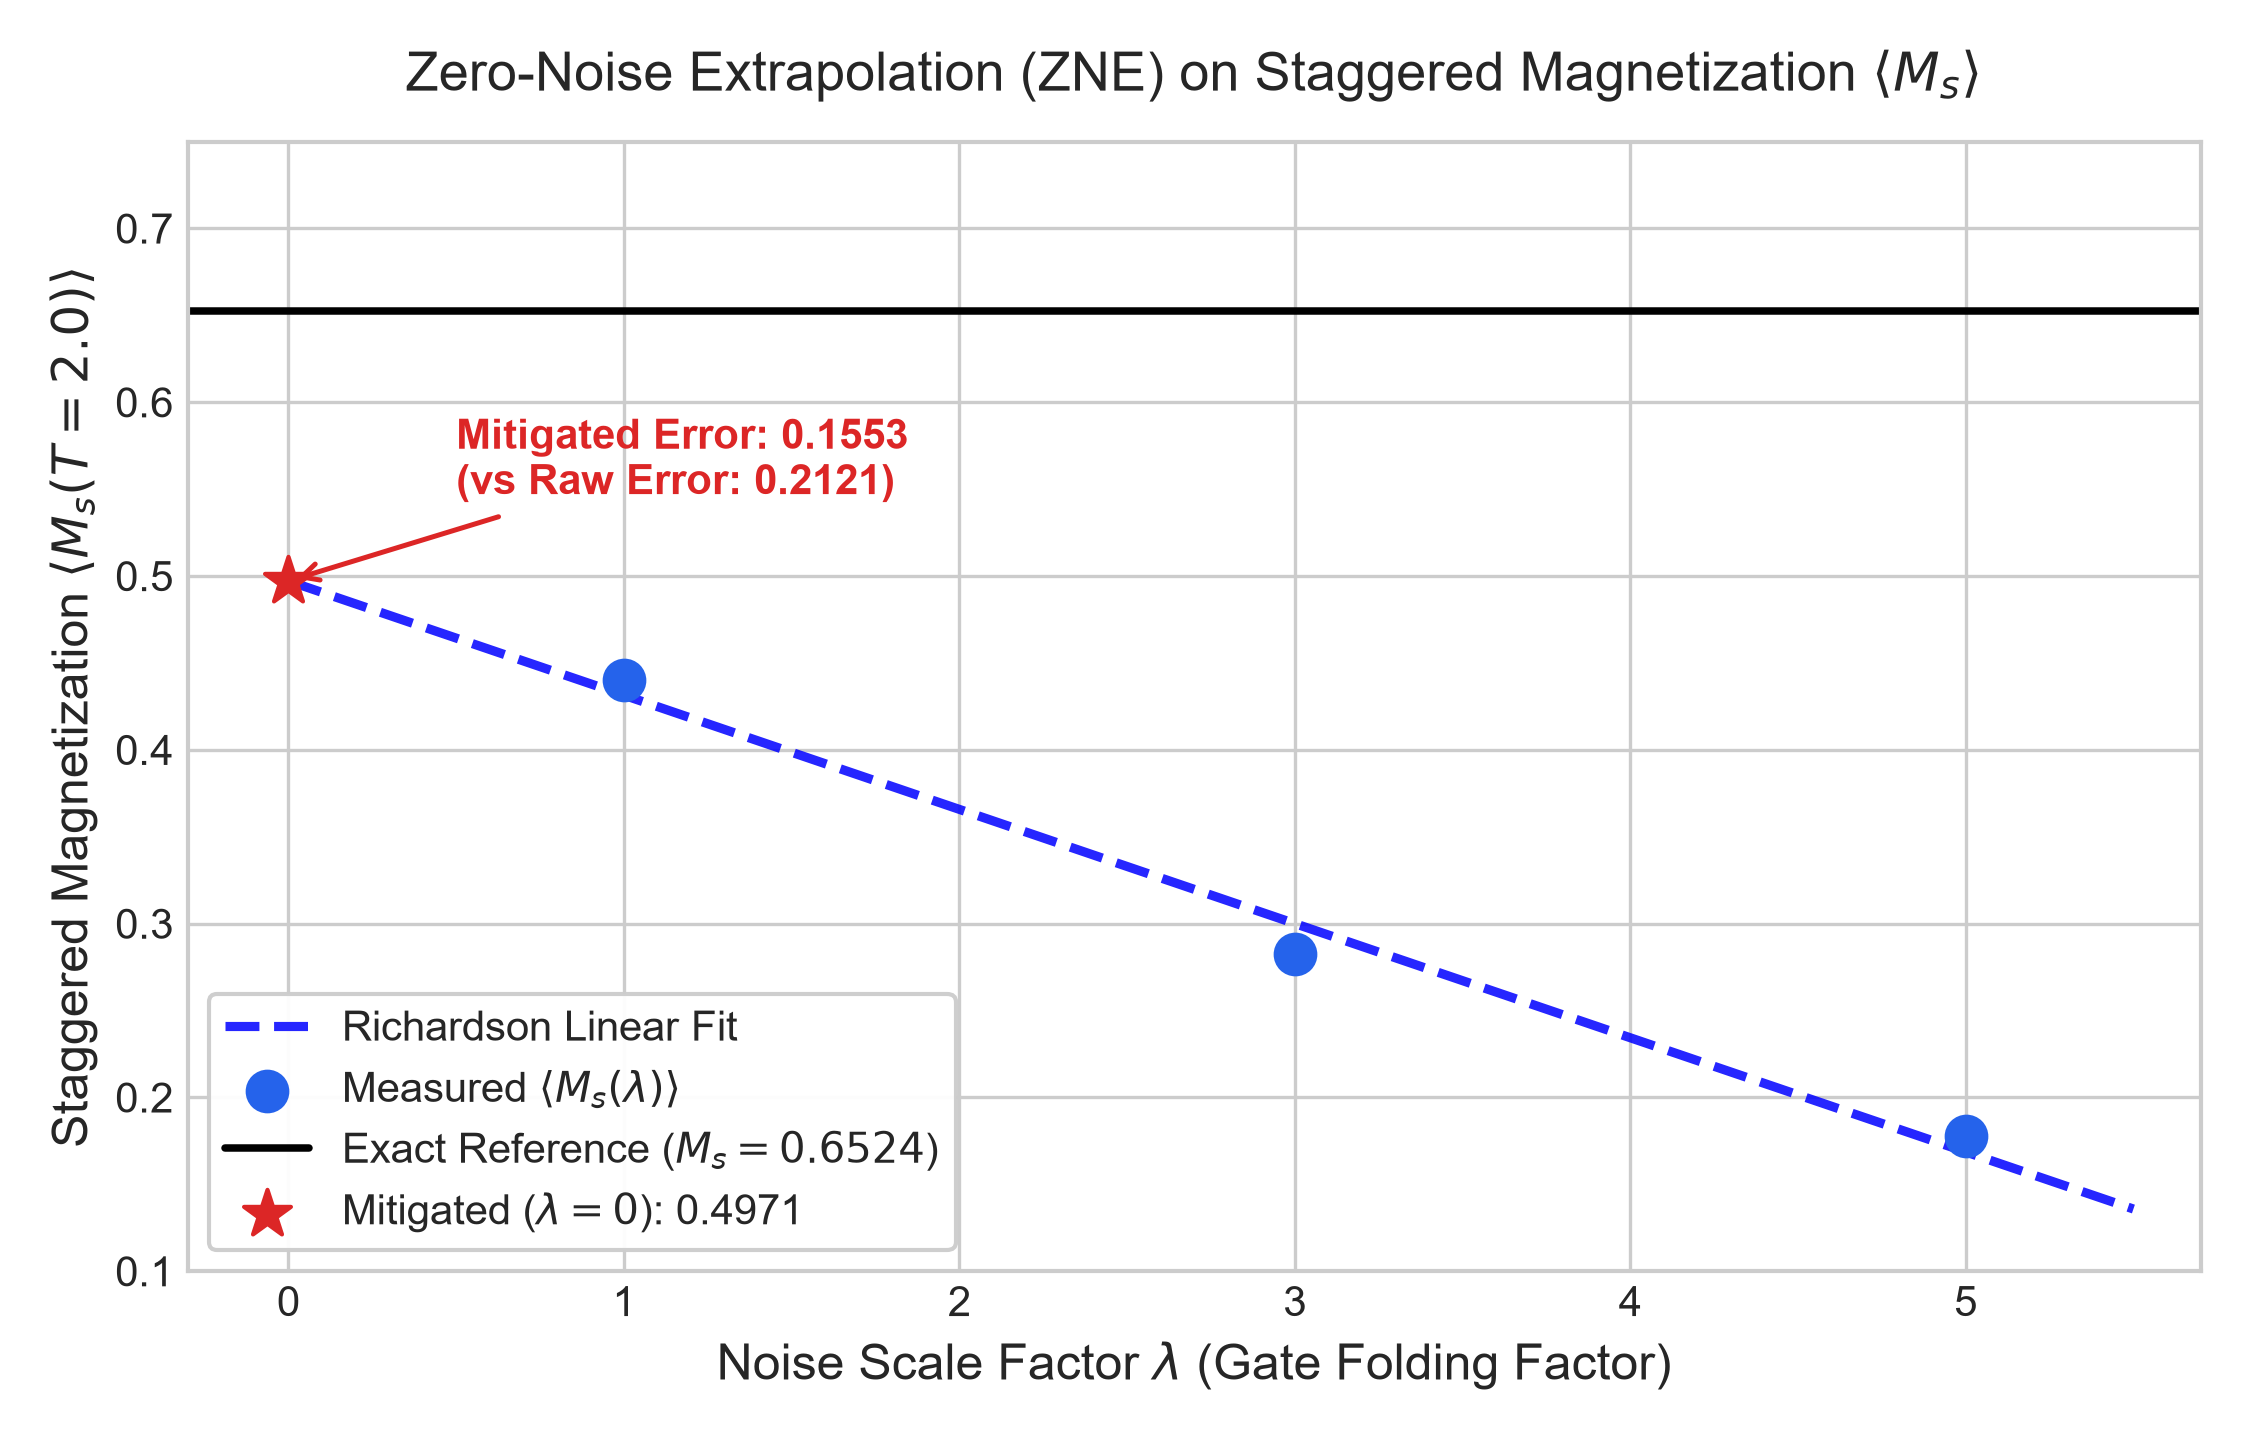

In [7]:
df_mit = pd.read_csv(ROOT / 'results' / 'tables' / 'mitigation.csv')
display(df_mit)

Image(str(ROOT / 'results' / 'figures' / 's3_zne_mitigation.png'))

## 7. Complete Phase 2 Scan Dataset (`s3_scan.csv`)
Below is the complete 60-row dataset recording noisy density-matrix fidelity $\mathcal{F}$, ideal Trotter fidelity, noisy staggered magnetization $M_s \pm \mathrm{SE}$, exact $M_s$, logical 2Q gates, routing SWAP 2Q gates, and total CX gates.

In [8]:
df_scan = pd.read_csv(ROOT / 'results' / 'tables' / 's3_scan.csv')
print(f'Total evaluated benchmark rows: {len(df_scan)}')
display(df_scan.head(15))

Total evaluated benchmark rows: 60


,processor,noise_scale,steps,fidelity_noisy,fidelity_trotter_ideal,ms_noisy,ms_noisy_se,ms_exact,logical_2q,swap_2q,two_q
0,Processor A,1.0,1,0.110107,0.115037,-0.626343,0.006166,0.652444,8,3,11
1,Processor A,1.0,2,0.261911,0.289041,0.122803,0.010875,0.652444,16,9,25
2,Processor A,1.0,3,0.068498,0.065841,0.129639,0.008951,0.652444,24,15,39
3,Processor A,1.0,4,0.404977,0.517567,0.313110,0.009697,0.652444,32,21,53
4,Processor A,1.0,5,0.546396,0.759999,0.368530,0.010233,0.652444,40,27,67
5,Processor A,1.0,6,0.577419,0.864191,0.369751,0.010428,0.652444,48,33,81
6,Processor A,1.0,7,0.569743,0.914448,0.362427,0.010534,0.652444,56,39,95
7,Processor A,1.0,8,0.548003,0.941669,0.347168,0.010523,0.652444,64,45,109
8,Processor A,1.0,10,0.493125,0.968139,0.307495,0.010440,0.652444,80,57,137
9,Processor A,1.0,12,0.438436,0.979984,0.259766,0.010357,0.652444,96,69,165


## 8. Provenance & Backward Compatibility Verification
Processor A is the 5-qubit fixed baseline graph loaded from `processors/processor_A.json` with 5 physical qubits. Processor B is the 7-qubit / 9-qubit heavy-hex-inspired graph loaded from `processors/processor_B.json`. Circuit metrics track Depth, two-qubit gate count, SWAP count, and physical qubits. The legacy 3-qubit practice demonstrator can be verified via `run_benchmark()`.

In [9]:
# Verification of Phase 1 Practice Demonstrator for provenance check
from scripts.run_practice import run_benchmark
practice_res = run_benchmark()
display(practice_res)

,physical_qubits,depth,two_qubit_gate_count,swap_count,routing_two_qubit_gate_count,algorithmic_two_qubit_gate_count,logical_qubits,mean_fidelity,fidelity_std,fidelity_stderr,...,measured_z0_expectation_std,trajectories,seed,p1,p2,readout_error,compilation_baseline,processor,processor_name,processor_source
0,5.0,8.0,4.0,0.0,0.0,4.0,3.0,0.961080,0.167895,0.003754,...,0.197977,2000.0,2026.0,0.001,0.01,0.01,deterministic reference routing,A,processor_A,source_document
1,7.0,32.0,28.0,8.0,24.0,4.0,3.0,0.782248,0.393610,0.008801,...,0.422881,2000.0,2026.0,0.001,0.01,0.01,contemporary compilation baseline,B,processor_B,source_document
